# 3. Out-of-sample test

The only honest way to compare covariance estimators is to use them: each month, estimate the matrix from past returns, build the minimum-variance portfolio, hold it for a month, and measure the risk that was actually realised.

Three estimators are compared:

* **Sample**: the standard estimator;
* **Ledoit-Wolf**: linear shrinkage of the sample matrix towards a multiple of the identity, with an optimal intensity computed from the data;
* **RMT clipping**: sample volatilities with a correlation matrix cleaned by eigenvalue clipping.

All strategies are tested on the same dates, from 2013, with a transaction cost of 5 basis points.

In [1]:
import sys
sys.path.insert(0, "..")  # make the `portfolio` package importable from the notebooks folder

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from portfolio import covariance as cov
from portfolio import load_prices, metrics, optimizer, rmt, run_backtest, sector_of, simulate_returns, split_benchmark, to_returns
from portfolio.backtest import equal_weight_strategy, max_sharpe_strategy, min_variance_strategy, risk_parity_strategy
from portfolio.plotting import use_style, BLUE, ORANGE, AQUA, YELLOW, MUTED, INK_SOFT, GRID

use_style()
pd.options.display.float_format = "{:.3f}".format

returns, benchmark = split_benchmark(to_returns(load_prices("../data/prices.csv")))
sectors = sector_of(returns.columns)
COLORS = {"Sample": ORANGE, "Ledoit-Wolf": AQUA, "RMT clipping": BLUE, "Equal weight": MUTED}
print(f"{returns.shape[1]} stocks, {len(returns):,} trading days, {returns.index[0]:%Y-%m-%d} to {returns.index[-1]:%Y-%m-%d}")

104 stocks, 4,242 trading days, 2010-01-05 to 2026-11-13


In [2]:
FIRST_TEST_DAY = 756   # three years of history before the first test date

def backtest(strategies, window=252, cost_bps=5):
    return run_backtest(returns.iloc[FIRST_TEST_DAY - window:], strategies, window=window, cost_bps=cost_bps)

def report(result):
    table = metrics.summary(result.returns, result.turnover)
    table["Realised / predicted variance"] = result.risk_underestimation
    return table

print(f"Test period: {returns.index[FIRST_TEST_DAY]:%Y-%m-%d} to {returns.index[-1]:%Y-%m-%d}")

Test period: 2013-01-07 to 2026-11-13


## 3.1 Minimum variance without constraints

With no constraint other than full investment, the optimiser is free to go long and short and to exploit every estimated correlation. This is where estimation noise does the most damage. One year of data (252 days) for 104 stocks gives $N/T = 0.41$.

In [3]:
long_short = backtest({name: min_variance_strategy(estimator, long_only=False) for name, estimator in cov.ESTIMATORS.items()}
                      | {"Equal weight": equal_weight_strategy()})
report(long_short).style.format({"Annual return": "{:.1%}", "Volatility": "{:.1%}", "Sharpe ratio": "{:.2f}", "Max drawdown": "{:.1%}",
                                 "Annual turnover": "{:.1f}", "Realised / predicted variance": "{:.2f}"})

,Annual return,Volatility,Sharpe ratio,Max drawdown,Annual turnover,Realised / predicted variance
Sample,10.8%,14.4%,0.79,-30.3%,15.8,4.19
Ledoit-Wolf,12.0%,12.9%,0.95,-23.7%,8.7,2.64
RMT clipping,11.3%,13.2%,0.88,-22.3%,5.8,2.65
Equal weight,15.8%,15.7%,1.01,-34.2%,0.3,1.00


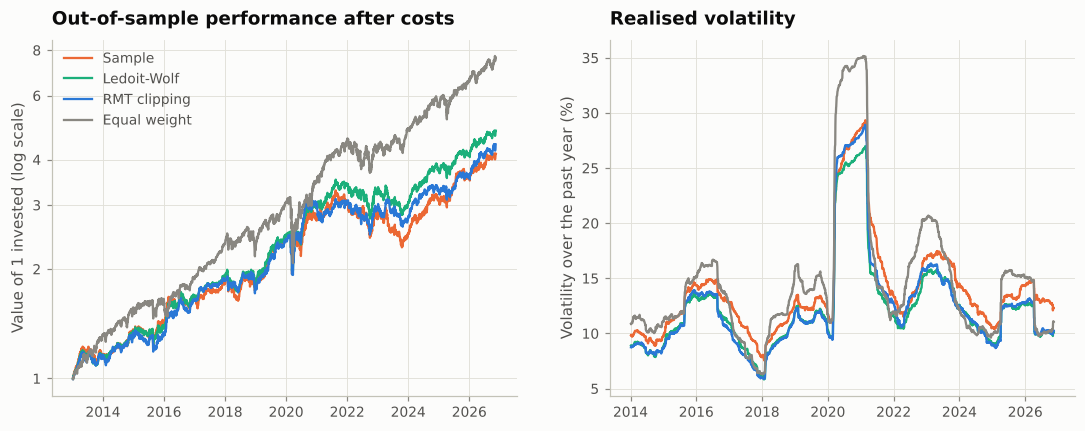

In [4]:
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.2))
for name in long_short.returns.columns:
    wealth = (1 + long_short.returns[name]).cumprod()
    left.plot(wealth.index, wealth, color=COLORS[name], linewidth=1.5, label=name)
    rolling = long_short.returns[name].rolling(252).std() * np.sqrt(252)
    right.plot(rolling.index, 100 * rolling, color=COLORS[name], linewidth=1.5, label=name)
left.set_yscale("log"); left.set_yticks([1, 2, 3, 4, 6, 8], ["1", "2", "3", "4", "6", "8"]); left.minorticks_off()
left.set_ylabel("Value of 1 invested (log scale)"); left.set_title("Out-of-sample performance after costs"); left.legend()
right.set_ylabel("Volatility over the past year (%)"); right.set_title("Realised volatility");

In [5]:
gross = [(long_short.weights[name].abs().sum(axis=1).mean(), (long_short.weights[name] < 0).sum(axis=1).mean())
         for name in cov.ESTIMATORS]
pd.DataFrame(gross, index=list(cov.ESTIMATORS), columns=["Average gross exposure", "Average number of short positions"]).style.format(
    {"Average gross exposure": "{:.0%}", "Average number of short positions": "{:.0f}"})

,Average gross exposure,Average number of short positions
Sample,563%,46
Ledoit-Wolf,380%,43
RMT clipping,313%,46


The *realised / predicted variance* column is the key diagnostic. Each month the estimator forecasts the variance of its own optimal portfolio; the ratio compares the realised variance with that forecast. For the equal-weight portfolio, which involves no optimisation, the ratio is close to 1. For optimised portfolios it is well above 1: the optimiser picks the combinations whose risk is most under-estimated.

## 3.2 The effect of the amount of data

The same experiment with estimation windows from six months to three years:

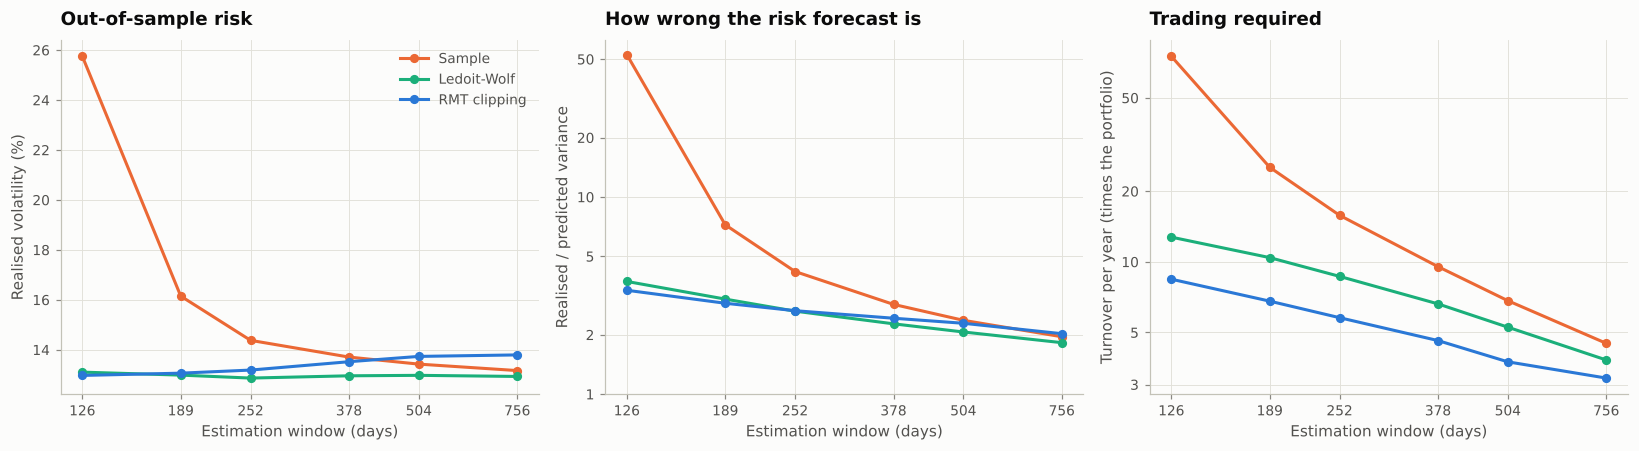

In [6]:
rows = []
for window in [126, 189, 252, 378, 504, 756]:
    result = backtest({name: min_variance_strategy(estimator, long_only=False) for name, estimator in cov.ESTIMATORS.items()},
                      window=window, cost_bps=0)
    for name in cov.ESTIMATORS:
        rows.append({"window": window, "N/T": returns.shape[1] / window, "estimator": name,
                     "vol": metrics.annualised_volatility(result.returns[name]),
                     "ratio": result.risk_underestimation[name], "turnover": result.turnover[name]})
sweep = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, column, ylabel, title in [(axes[0], "vol", "Realised volatility (%)", "Out-of-sample risk"),
                                  (axes[1], "ratio", "Realised / predicted variance", "How wrong the risk forecast is"),
                                  (axes[2], "turnover", "Turnover per year (times the portfolio)", "Trading required")]:
    for name, group in sweep.groupby("estimator", sort=False):
        ax.plot(group["window"], group[column] * (100 if column == "vol" else 1), marker="o", color=COLORS[name], label=name)
    ax.set_xscale("log"); ax.set_xticks([126, 189, 252, 378, 504, 756], ["126", "189", "252", "378", "504", "756"])
    if column != "vol":
        ax.set_yscale("log")
        ticks = [1, 2, 5, 10, 20, 50] if column == "ratio" else [3, 5, 10, 20, 50]
        ax.set_yticks(ticks, [str(t) for t in ticks])
    ax.minorticks_off(); ax.set_xlabel("Estimation window (days)"); ax.set_ylabel(ylabel); ax.set_title(title)
axes[0].legend(); fig.tight_layout()

In [7]:
sweep.pivot(index=["window", "N/T"], columns="estimator", values="vol")[list(cov.ESTIMATORS)].style.format("{:.1%}")

,estimator,Sample,Ledoit-Wolf,RMT clipping
window,N/T,,,
126,0.825397,25.8%,13.1%,13.0%
189,0.550265,16.1%,13.0%,13.1%
252,0.412698,14.4%,12.9%,13.2%
378,0.275132,13.7%,13.0%,13.5%
504,0.206349,13.4%,13.0%,13.7%
756,0.137566,13.2%,12.9%,13.8%


## 3.3 With a long-only constraint

Most real portfolios cannot short. Jagannathan and Ma (2003) showed that forbidding short positions is itself a form of shrinkage: it prevents the optimiser from acting on the most extreme (and noisiest) covariance estimates.

In [8]:
long_only = backtest({name: min_variance_strategy(estimator, long_only=True) for name, estimator in cov.ESTIMATORS.items()}
                     | {"Risk parity (RMT)": risk_parity_strategy(cov.rmt_clipped), "Equal weight": equal_weight_strategy()})
table = report(long_only)
if benchmark is not None:
    bench = benchmark.reindex(long_only.returns.index)
    table.loc["S&P 500 (SPY)"] = [metrics.annualised_return(bench), metrics.annualised_volatility(bench),
                                  metrics.sharpe_ratio(bench), metrics.max_drawdown(bench), np.nan, np.nan]
table.style.format({"Annual return": "{:.1%}", "Volatility": "{:.1%}", "Sharpe ratio": "{:.2f}", "Max drawdown": "{:.1%}",
                    "Annual turnover": "{:.2f}", "Realised / predicted variance": "{:.2f}"}, na_rep="")

,Annual return,Volatility,Sharpe ratio,Max drawdown,Annual turnover,Realised / predicted variance
Sample,10.6%,12.3%,0.88,-23.8%,2.21,1.37
Ledoit-Wolf,10.7%,12.3%,0.88,-25.1%,2.02,1.42
RMT clipping,10.1%,12.7%,0.82,-26.5%,2.08,1.42
Risk parity (RMT),14.7%,14.6%,1.01,-31.9%,0.36,1.04
Equal weight,15.8%,15.7%,1.01,-34.2%,0.27,1.00
S&P 500 (SPY),14.5%,16.8%,0.89,-33.7%,,


In [9]:
held = pd.Series({name: (long_only.weights[name] > 1e-4).sum(axis=1).mean() for name in cov.ESTIMATORS})
print("Average number of stocks held by the long-only minimum-variance portfolio:")
print(held.round(1).to_string())

Average number of stocks held by the long-only minimum-variance portfolio:
Sample         23.600
Ledoit-Wolf    27.900
RMT clipping   23.800


## 3.4 Maximum Sharpe with historical means

For completeness: the full Markowitz portfolio, with expected returns estimated by the mean over the same window.

In [10]:
sharpe = backtest({"Max Sharpe, Sample": max_sharpe_strategy(cov.sample_covariance),
                   "Max Sharpe, RMT clipping": max_sharpe_strategy(cov.rmt_clipped),
                   "Equal weight": equal_weight_strategy()})
report(sharpe).style.format({"Annual return": "{:.1%}", "Volatility": "{:.1%}", "Sharpe ratio": "{:.2f}", "Max drawdown": "{:.1%}",
                             "Annual turnover": "{:.2f}", "Realised / predicted variance": "{:.2f}"})

,Annual return,Volatility,Sharpe ratio,Max drawdown,Annual turnover,Realised / predicted variance
"Max Sharpe, Sample",13.8%,17.6%,0.82,-27.2%,4.11,1.38
"Max Sharpe, RMT clipping",13.4%,17.7%,0.80,-28.0%,4.02,1.37
Equal weight,15.8%,15.7%,1.01,-34.2%,0.27,1.00


## Summary

**Where cleaning helps.** Without constraints and with one year of data, the sample matrix gives the riskiest minimum-variance portfolio (14.4% realised volatility against 12.9% for Ledoit-Wolf and 13.2% for RMT clipping), holds the largest positions (gross exposure 563% against 380% and 313%) and trades the most (15.8 times the portfolio per year against 8.7 and 5.8). With six months of data the sample portfolio reaches 25.8% volatility while both cleaned versions stay at 13%.

**Where it does not.** With two or three years of data the three estimators are within a point of each other, and RMT clipping becomes slightly *worse* than the sample matrix (13.7% against 13.4% at 504 days): once noise is small, averaging the small eigenvalues discards real information. Ledoit-Wolf is the most robust choice here, at about 13% for every window. With a long-only constraint, cleaning brings nothing: all three give about 12.3 to 12.7%, lower than any unconstrained version. The constraint already does the regularisation, as Jagannathan and Ma predicted.

**Risk forecasts stay too low.** Even the cleaned estimators realise about 2.6 times the variance they forecast for their own unconstrained portfolio. Cleaning removes sampling noise, but not the fact that volatilities and correlations change over time, nor the selection bias of the optimiser.

**Returns.** Minimum-variance portfolios did what they are built for (lower volatility and smaller drawdowns than equal weight), but over this period the equal-weight portfolio had the highest return and Sharpe ratio (1.01). Maximum-Sharpe portfolios built on historical means did worse than equal weight (0.82), whatever the covariance estimator.

**Caveats.** The universe is made of companies that are large *today* and have a full price history since 2010, which favours past winners (survivorship bias) and inflates every return shown here, the equal-weight one most of all. The comparison of *risks* between estimators is much less affected. One market and one fourteen-year period are not a general proof.